In [1]:
%matplotlib inline
# Shared settings — run from llm_based_abm/ with the dev Python environment.
# Only saved data are read. This notebook never calls an LLM API.
import os, json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import colors as mcolors
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from IPython.display import display
from wordcloud import WordCloud, STOPWORDS

GREEN = '#285304'      
ORANGE = '#D87540'     
INK = '#243126'
GRAY = '#7C827A'
FIGURE_DIR = 'figures'
SAVE_FORMATS = ['png', 'svg']
SAVE_DPI = 300
FONT = 'Arial'
TITLE_FONT = 'Times New Roman'
WORD_FONT = '/System/Library/Fonts/Supplemental/Arial.ttf'

METHOD_ORDER = ['weekday_mean', 'ridge', 'rule_daily', 'direct_few',
                'role_with_history']
LABELS = {'weekday_mean': 'Weekday Average', 'ridge': 'Ridge Regression', 'rule_daily': 'Rule-Based ABM',
          'direct_few': 'Direct LLM', 'role_no_history': 'Role LLM (No History)',
          'role_with_history': 'Role LLM'}
EVENTS = {'Extreme_0729': '2023-07-29', 'Extreme_0813': '2023-08-13',
          'Extreme_0929': '2023-09-29', 'Extreme_1007': '2023-10-07'}
EVENT_LABELS = {'Extreme_0729': 'Jul 29', 'Extreme_0813': 'Aug 13',
                'Extreme_0929': 'Sep 29', 'Extreme_1007': 'Oct 7'}
PRICES = {'Doubao Lite': {'input': .8, 'cached': .16, 'output': 2.7},
          'Doubao Pro': {'input': 6., 'cached': 1.2, 'output': 30.}}

plt.rcParams.update({'font.family': FONT, 'font.size': 11, 'axes.titlesize': 16, 'axes.titlecolor': 'black',
                     'axes.labelsize': 11, 'figure.dpi': 110, 'savefig.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#CFD4CB', 'axes.labelcolor': INK,
                     'xtick.color': '#60675F', 'ytick.color': '#60675F',
                     'svg.fonttype': 'none'})
os.makedirs(FIGURE_DIR, exist_ok=True)

def tint(color, strength):
    return tuple(strength*np.array(mcolors.to_rgb(color)) + (1-strength))

def style(ax, grid='y'):
    ax.set_axisbelow(True)
    ax.grid(axis=grid, color='#E8ECE4', linewidth=.7)
    ax.tick_params(length=0, pad=7)

def rank_colors(values, color, low=.35, high=1.):
    # Equal alpha steps assigned by value rank; bar positions stay fixed.
    values = pd.Series(np.asarray(values, dtype=float))
    ranks = values.rank(method='average').to_numpy()-1
    alpha = low+(high-low)*ranks/max(len(values)-1, 1)
    return [mcolors.to_rgba(color, value) for value in alpha]

def add_legend(ax, loc='upper right', ncol=1, **kwargs):
    return ax.legend(loc=loc, ncol=ncol, frameon=True, fancybox=False,
                     framealpha=.96, facecolor='white', edgecolor='#A8B09F',
                     fontsize=9, **kwargs)

def finish(fig, name):
    for ax in fig.axes:
        for loc in ['left', 'center', 'right']:
            text = ax.get_title(loc=loc)
            if text:
                ax.set_title(text, loc=loc, color='black', fontsize=16,
                             fontfamily=TITLE_FONT, fontweight='bold', pad=12)
    fig.tight_layout(pad=1.25)
    for extension in SAVE_FORMATS:
        fig.savefig(f'{FIGURE_DIR}/{name}.{extension}', dpi=SAVE_DPI, facecolor='white')
    plt.show()
    plt.close(fig)

def cost(frame, model='Doubao Lite'):
    rate = PRICES[model]
    return ((frame.input_tokens-frame.cached_tokens)*rate['input']
            + frame.cached_tokens*rate['cached'] + frame.output_tokens*rate['output'])/1e6

scores = pd.read_csv('figures/data/mainline_scores.csv').set_index('method')
predictions = pd.read_csv('figures/data/mainline_predictions.csv', dtype={'station_complex_id': str}, parse_dates=['date'])
usage = pd.read_csv('figures/data/lite_request_usage.csv')
history = pd.read_csv('figures/data/history_daily.csv', dtype={'station_complex_id': str}, parse_dates=['date'])
stations = pd.read_csv('figures/data/stations.csv', dtype={'station_complex_id': str}).set_index('station_complex_id')
# Shared method identity for time-series charts; order stays fixed in every legend.
LINE_STYLE = {'weekday_mean': (GRAY, ':', 's'), 'ridge': (tint(GREEN,.52), '--', 'D'),
              'rule_daily': (tint(GREEN,.74), '-.', '^'), 'direct_few': (ORANGE, '-', 'o'),
              'role_no_history': (tint(ORANGE,.62), '--', 'v'), 'role_with_history': (GREEN, '-', 'o')}


## 各模型整体表现

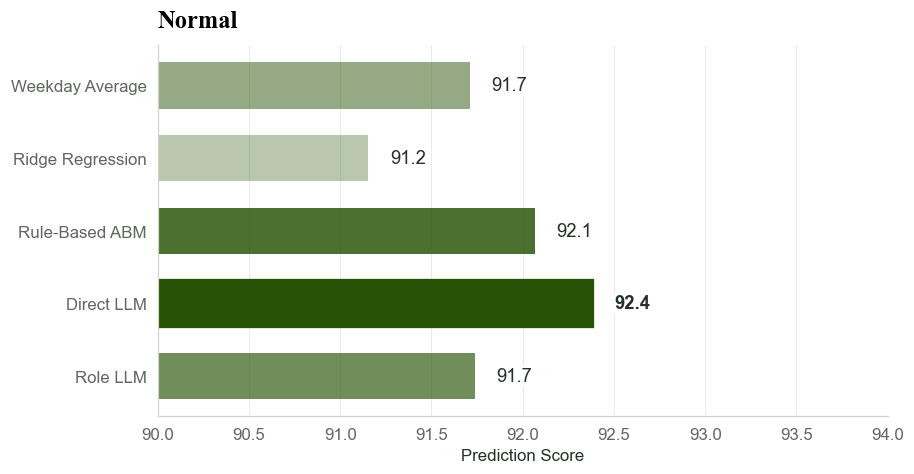

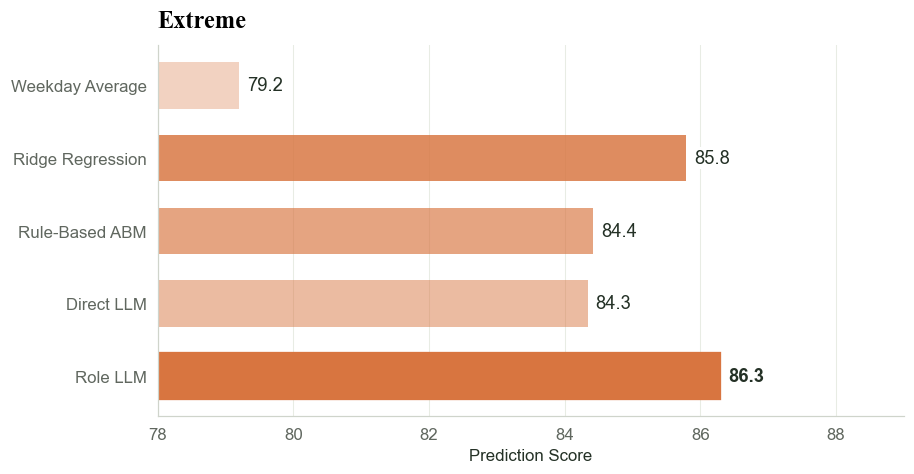

In [2]:
# C1 — Accuracy-score comparison. Fixed order; alpha encodes score, not ranking.
C1_SIZE = (8.5, 4.5)
C1_XLIM = {'Normal': (90, 94), 'Extreme': (78, 89)}
C1_ALPHA = (.32, 1.0)
C1_LABEL_SIZE = 12

for regime, base in [('Normal', GREEN), ('Extreme', ORANGE)]:
    values = scores[regime].reindex(METHOD_ORDER)
    bar_colors = rank_colors(values, base, *C1_ALPHA)
    fig, ax = plt.subplots(figsize=C1_SIZE)
    y = np.arange(len(METHOD_ORDER))
    bars = ax.barh(y, values, color=bar_colors, height=.64)
    winner = int(np.argmax(values.to_numpy()))
    bars[winner].set_edgecolor(base); bars[winner].set_linewidth(1.5)
    ax.set_yticks(y, [LABELS[m] for m in METHOD_ORDER])
    ax.invert_yaxis(); ax.set_xlim(C1_XLIM[regime])
    for i, value in enumerate(values):
        ax.text(value+.12, i, f'{value:.1f}', va='center', fontsize=C1_LABEL_SIZE,
                weight='bold' if i==winner else 'normal', color=INK,
                bbox=dict(facecolor='white', edgecolor='none', pad=1.1))
    ax.set_title(regime, loc='left', color='black', fontfamily=TITLE_FONT, fontsize=16, fontweight='bold', pad=17)
    ax.set_xlabel('Prediction Score')
    style(ax, 'x')
    finish(fig, f'C1_{regime.lower()}')


## 运行时间与花费

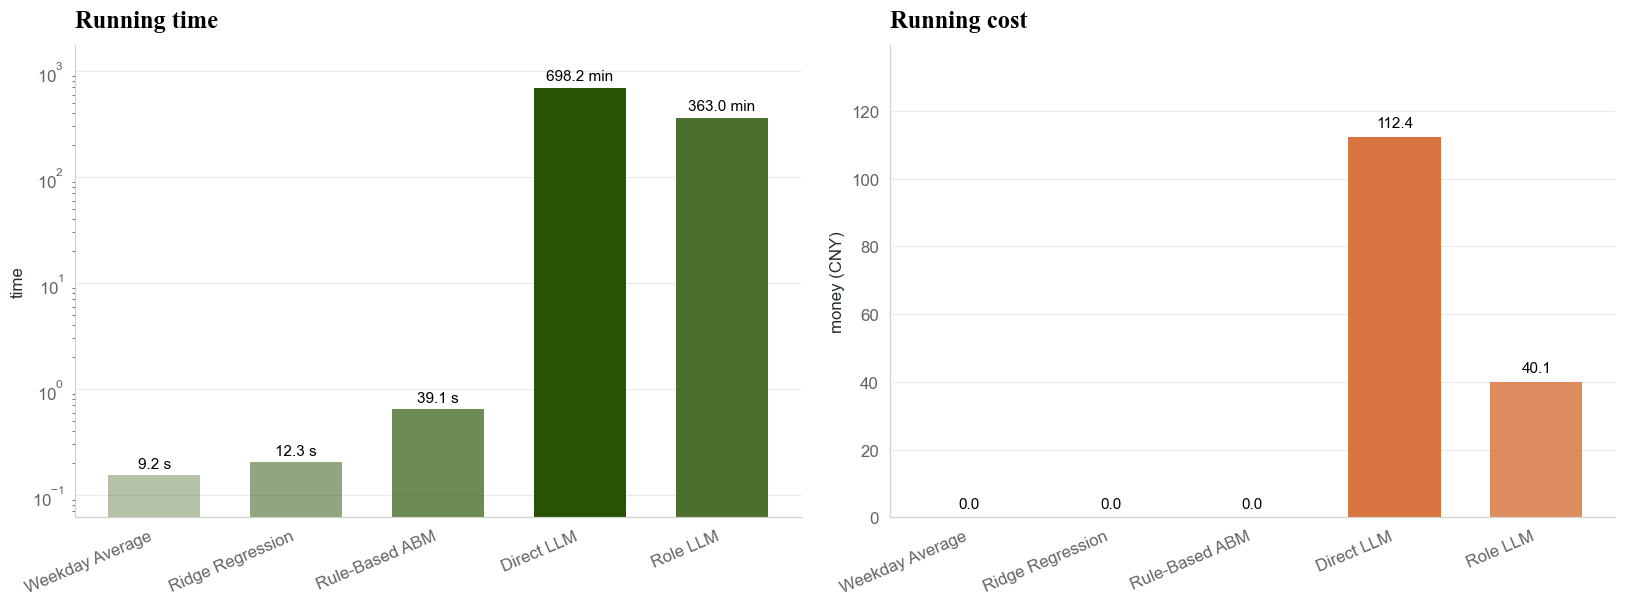

In [3]:
# C2 — Computation/service workload and token-cost estimate, in fixed method order.
# Time = one measured offline numerical replay + SUM of original API request seconds.
# This is serial-equivalent work, NOT the original parallel wall-clock duration.
C2_SIZE = (15, 5.7)
C2_TIME_LOG_SCALE = True
C2_LABEL_ROTATION = 23

compute = pd.read_csv('figures/data/offline_compute_runtime.csv').groupby('method').seconds.sum()
u = usage.assign(cost_cny=cost(usage)).groupby('method')[['api_seconds','cost_cny']].sum().reindex(METHOD_ORDER, fill_value=0)
minutes = (compute.reindex(METHOD_ORDER)+u.api_seconds)/60*5
money = u.cost_cny*25
fig, axes = plt.subplots(1, 2, figsize=C2_SIZE)
x = np.arange(len(METHOD_ORDER))
for ax, values, color, title, ylabel in [
    (axes[0], minutes, GREEN, 'Running time', 'time'),
    (axes[1], money, ORANGE, 'Running cost', 'money (CNY)')]:
    bars = ax.bar(x, values, color=rank_colors(values, color), width=.65)
    ax.set_xticks(x, [LABELS[m].replace(' LLM ', '\nLLM ') for m in METHOD_ORDER],
                  rotation=C2_LABEL_ROTATION, ha='right')
    ax.set_title(title, loc='left', fontfamily=TITLE_FONT, fontweight='bold')
    ax.set_ylabel(ylabel); style(ax)
    if ax is axes[0] and C2_TIME_LOG_SCALE:
        ax.set_yscale('log'); ax.set_ylim(minutes.min()*.4, minutes.max()*2.5)
        for b, value in zip(bars, values):
            ax.text(b.get_x()+b.get_width()/2, value*1.17, f'{value*60:.1f} s' if value<1 else f'{value:.1f} min', ha='center', fontsize=10)
    else:
        ax.set_ylim(0, max(values)*1.24)
        for b, value in zip(bars, values):
            ax.text(b.get_x()+b.get_width()/2, value+max(values)*.025, f'{value:.1f}', ha='center', fontsize=10)
finish(fig, 'C2_runtime_cost')


## 示例站点各模型预测结果

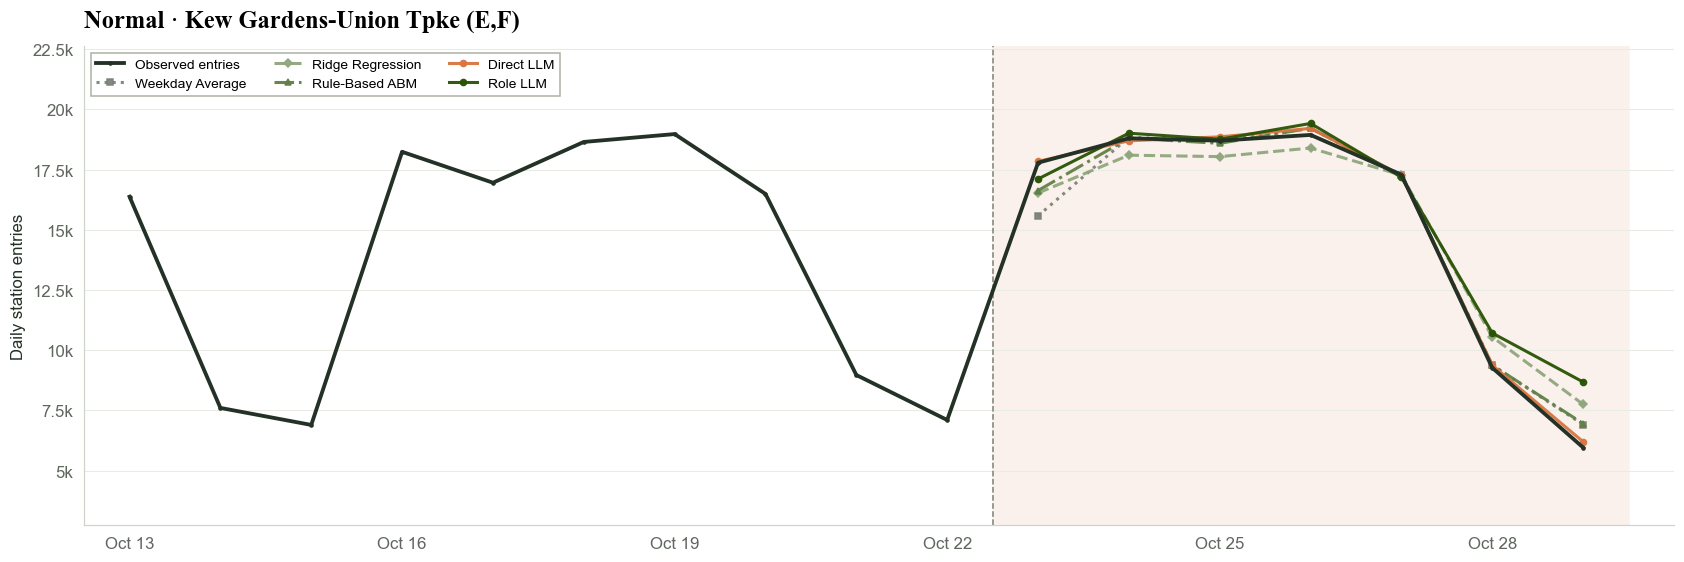

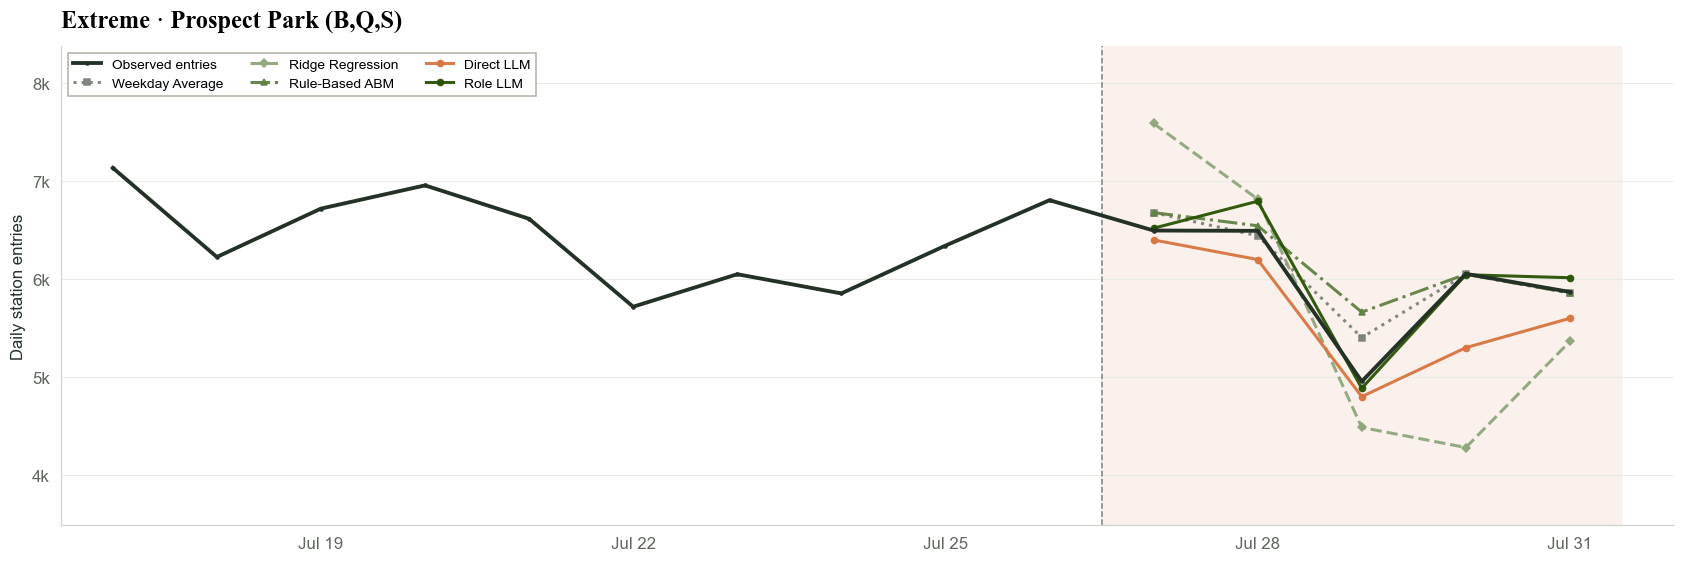

In [4]:
# C3 — One selected Normal case and one selected Extreme case; observations include history.
# Select the best full-window station case for the best LLM method in each regime.
# These are illustrative cases selected AFTER evaluation, not an unbiased test summary.
C3_SIZE = (15.5, 5.3)
C3_HISTORY_DAYS = 10
C3_LINE_WIDTH = 2.0
C3_OBSERVED_WIDTH = 2.5
C3_MARKER_SIZE = 4

selected = pd.read_csv('figures/data/selected_cases.csv', dtype={'station_complex_id': str})
for case in selected.itertuples():
    target = predictions[(predictions.task==case.task)&(predictions.station_complex_id==case.station_complex_id)]
    start, end = target.date.min(), target.date.max()
    observed = history[(history.station_complex_id==case.station_complex_id)
                       &history.date.between(start-pd.Timedelta(days=C3_HISTORY_DAYS), end)]
    fig, ax = plt.subplots(figsize=C3_SIZE)
    ax.axvspan(start-pd.Timedelta(hours=12), end+pd.Timedelta(hours=12), color=tint(ORANGE,.10), zorder=0)
    ax.plot(observed.date, observed.total_ridership, color=INK, lw=C3_OBSERVED_WIDTH,
            marker='.', ms=4, label='Observed entries', zorder=5)
    for method in METHOD_ORDER:
        line = target[target.method==method].sort_values('date')
        color, ls, marker = LINE_STYLE[method]
        ax.plot(line.date, line.predicted, color=color, ls=ls, marker=marker,
                lw=C3_LINE_WIDTH, ms=C3_MARKER_SIZE, label=LABELS[method], alpha=.95)
    ax.axvline(start-pd.Timedelta(hours=12), color=GRAY, ls='--', lw=1)
    station_name = stations.loc[case.station_complex_id, 'station_name']
    ax.set_title(f'{case.regime} · {station_name} ', loc='left',
                 fontfamily=TITLE_FONT, fontweight='bold')
    ax.set_ylabel('Daily station entries')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value/1000:g}k'))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.set_xlim(observed.date.min()-pd.Timedelta(hours=12), end+pd.Timedelta(days=1))
    ax.margins(y=.24)
    add_legend(ax, loc='upper left', ncol=3)
    style(ax)
    finish(fig, f'C3_{case.regime.lower()}_prediction')


## 重要结论1:加入历史（zero-shot vs few-shot）对于LLM的表现有较大提升

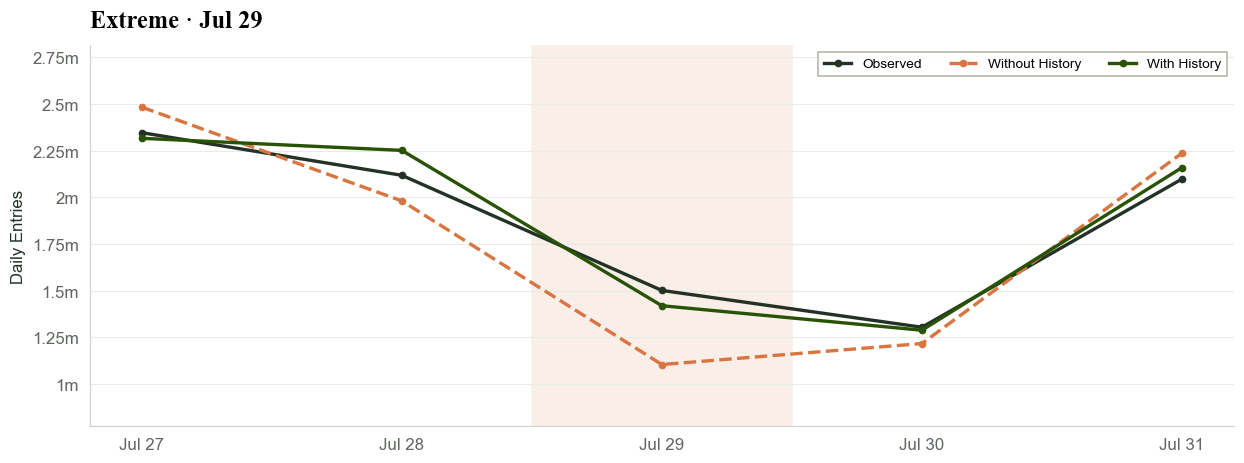

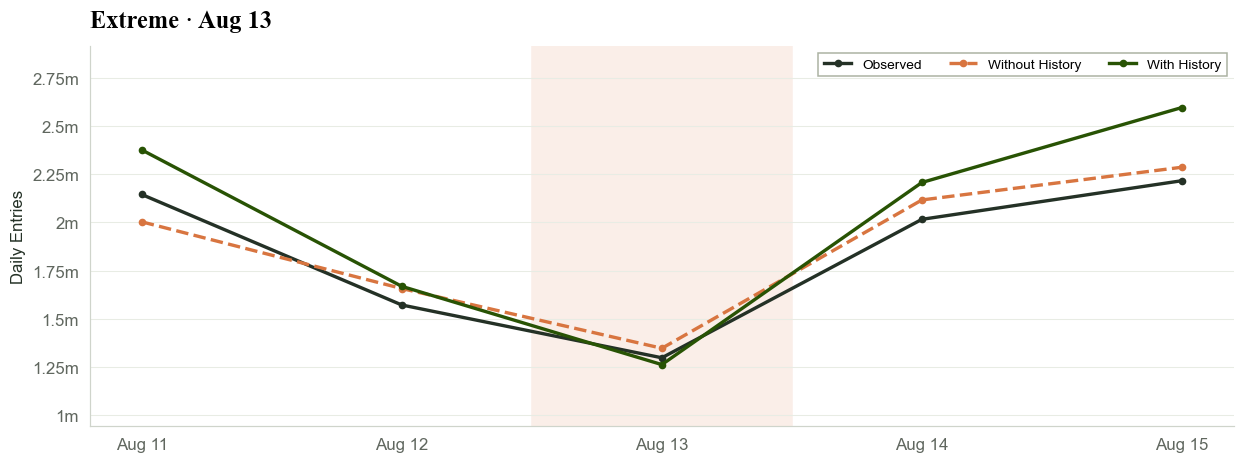

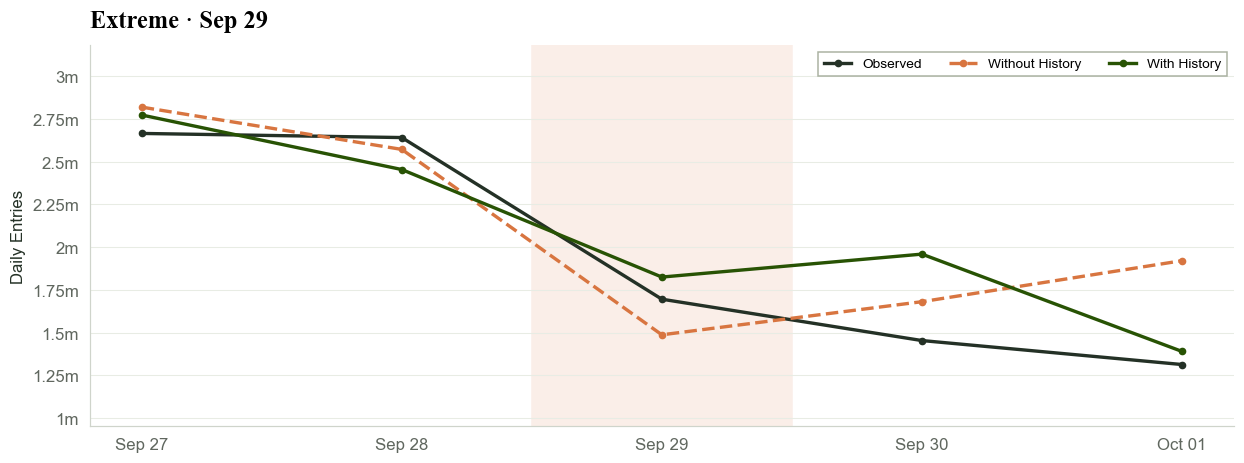

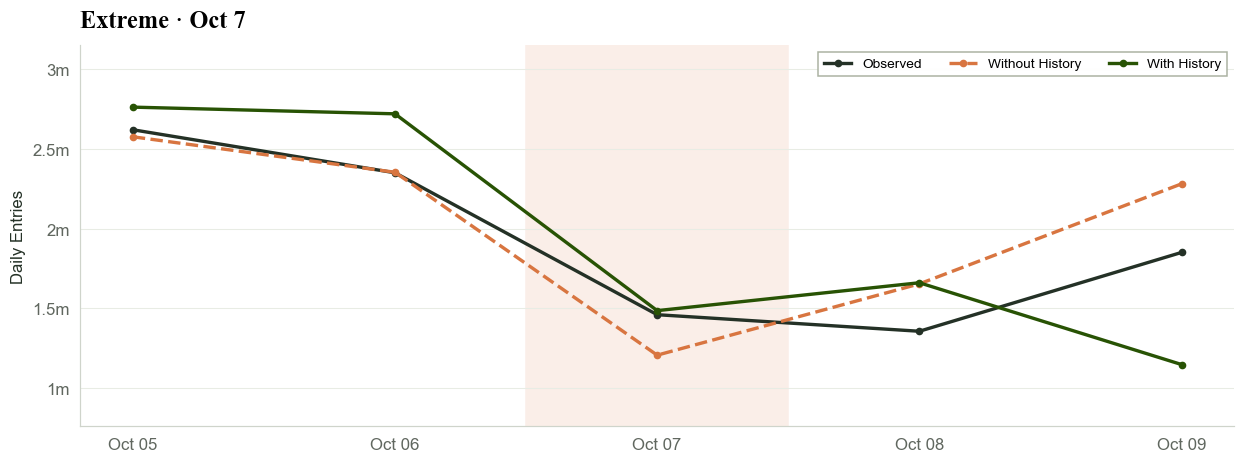

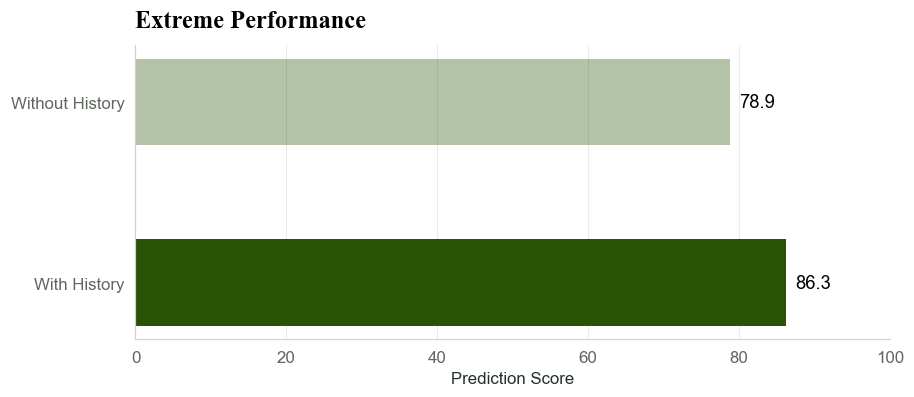

In [5]:
# C4 — Separate event figures and a separate overall history-input comparison.
# The dedicated ablation retains both arms; general model charts use Role LLM only.
C4_EVENT_SIZE = (11.5, 4.4)
C4_BAR_SIZE = (8.5, 3.8)
C4_LW = 2.2

for task, center_date in EVENTS.items():
    fig, ax = plt.subplots(figsize=C4_EVENT_SIZE)
    part = predictions[predictions.task==task]
    truth = part.drop_duplicates(['station_complex_id','date']).groupby('date').actual.sum()
    ax.plot(truth.index, truth, color=INK, lw=C4_LW, marker='o', ms=4, label='Observed')
    for method, color, ls, label in [('role_no_history', ORANGE, '--', 'Without History'),
                                      ('role_with_history', GREEN, '-', 'With History')]:
        line = part[part.method==method].groupby('date').predicted.sum()
        ax.plot(line.index, line, color=color, ls=ls, marker='o', ms=4, lw=C4_LW, label=label)
    ax.axvspan(pd.Timestamp(center_date)-pd.Timedelta(hours=12), pd.Timestamp(center_date)+pd.Timedelta(hours=12),
               color=tint(ORANGE,.12), zorder=0)
    ax.set_title("Extreme · " + EVENT_LABELS[task], loc='left')
    ax.set_xticks(truth.index); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.set_ylabel('Daily Entries'); ax.yaxis.set_major_formatter(FuncFormatter(lambda v,p: f'{v/1e6:g}m'))
    ax.margins(y=.24); add_legend(ax, loc='upper right', ncol=3); style(ax)
    finish(fig, 'C4_'+task.lower())

fig, ax = plt.subplots(figsize=C4_BAR_SIZE)
values = scores.loc[['role_no_history','role_with_history'], 'Extreme']
bars = ax.barh([0,1], values, color=rank_colors(values, GREEN), height=.48)
ax.set_yticks([0,1], ['Without History','With History']); ax.invert_yaxis()
ax.set_xlim(0,100); ax.set_xlabel('Prediction Score')
ax.set_title('Extreme Performance', loc='left')
for b,value in zip(bars,values):
    ax.text(value+1.2, b.get_y()+b.get_height()/2, f'{value:.1f}', va='center', fontsize=12)
style(ax, grid='x'); finish(fig, 'C4_role_history_comparison')


## 重要结论2:LLM-based 模型可以理解更加复杂的信息（具体降雨时段/周边大型活动信息等），进而提高准确率

#### 前面2个图：该天为极端天气，但是降雨集中在凌晨，加入该信息后准确率明显上升
#### 后面3个图：该站点服务 Citi Field 球场；9月16日有 Mets 主场比赛，而球队2023年赛季在10月1日结束，加入该信息后赛后的人群估计明显降低，准确率提高

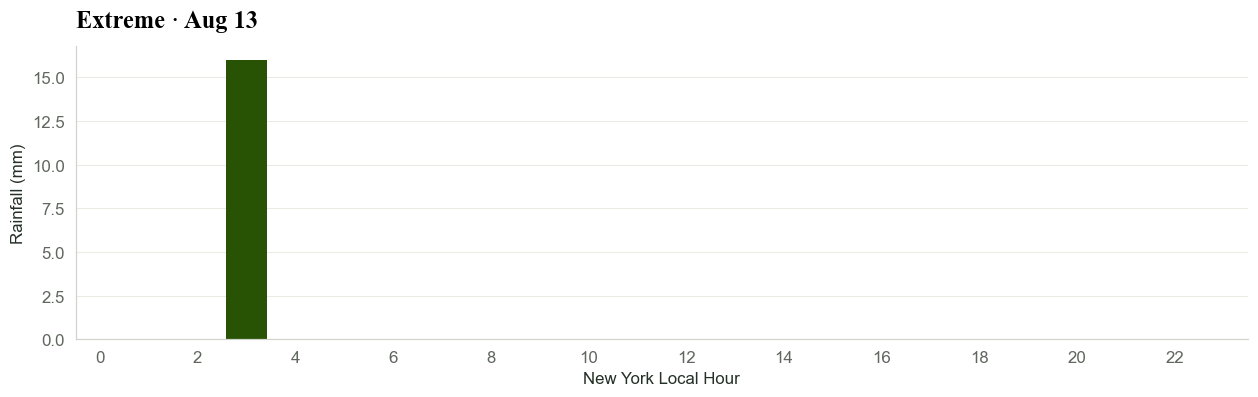

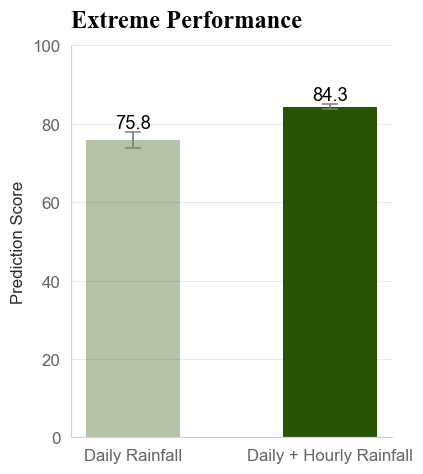

/opt/anaconda3/envs/dev/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


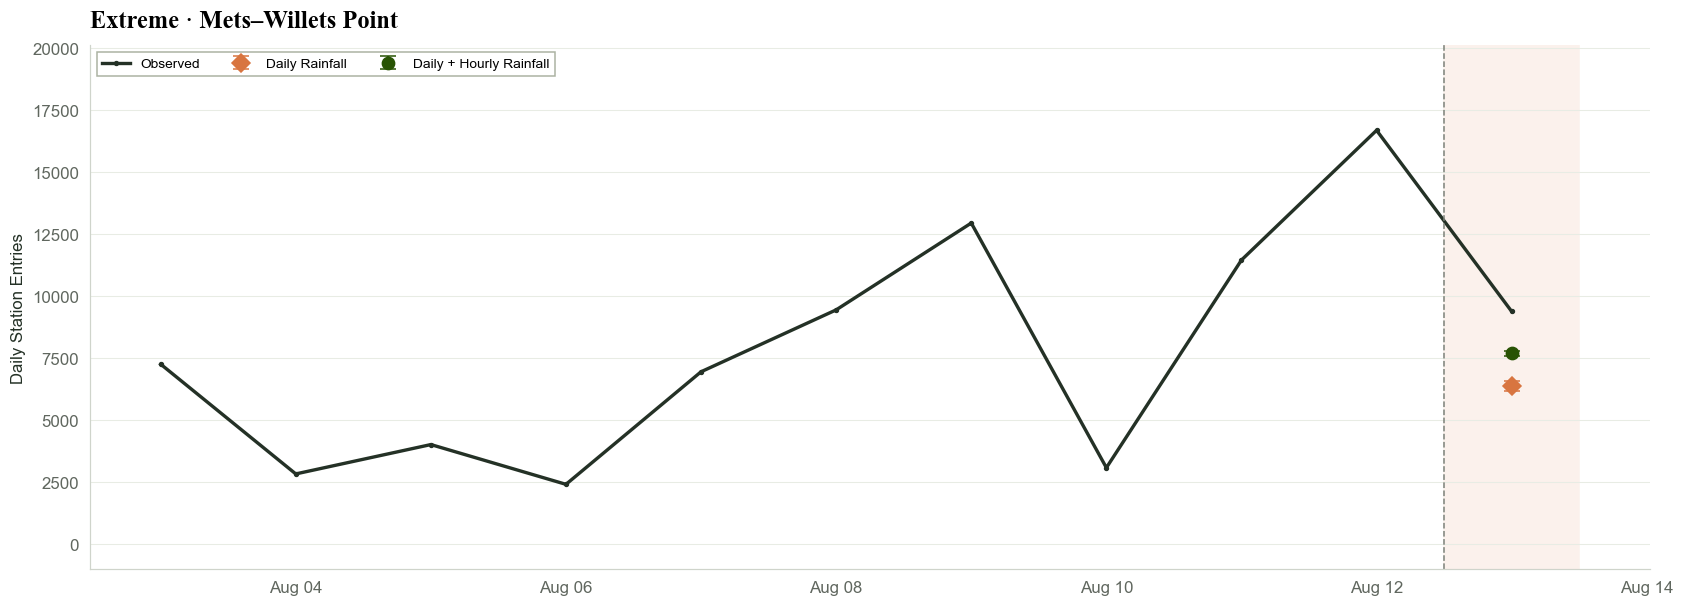

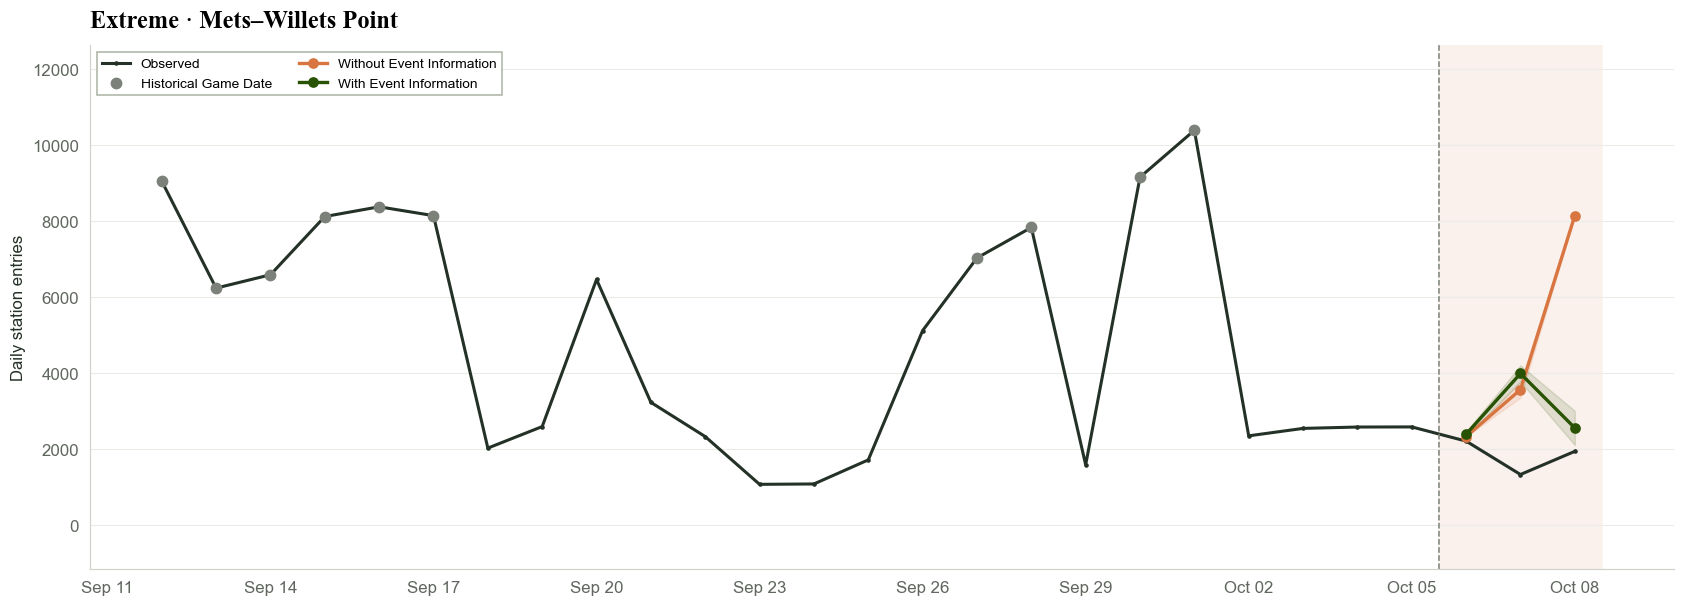

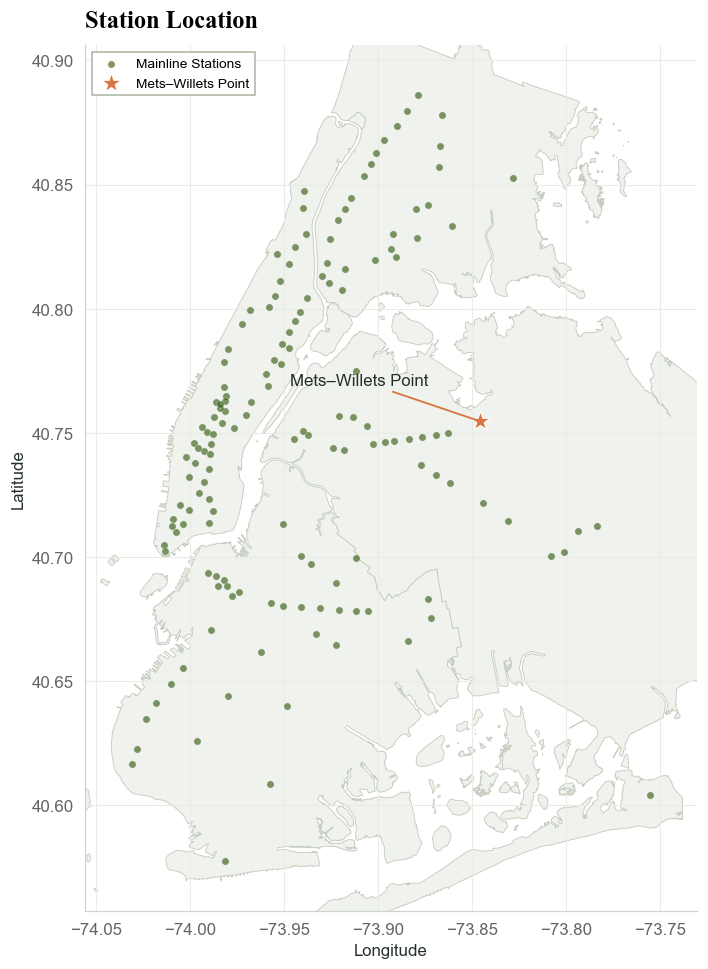

In [6]:
# C5 — Saved Direct LLM information ablations; both repeats are retained.
# Rain forecasts exist only on event center days, not a continuous forecast window.
C5_RAIN_SIZE = (11.5, 3.8)
C5_BAR_SIZE = (4, 4.5)
C5_RAIN_SERIES_SIZE = (15.5, 5.7)
C5_ACTIVITY_SIZE = (15.5, 5.7)
C5_MAP_SIZE = (8.5, 9)
C5_LW = 2.2
C5_ACTIVITY_METHOD = 'direct_few'
C5_STATION = '448'
C5_RAIN_DATE = pd.Timestamp('2023-08-13')

side = pd.read_csv('figures/data/side_predictions.csv', dtype={'station_complex_id': str}, parse_dates=['date'])
weather = pd.read_csv('figures/data/weather_hourly.csv', parse_dates=['timestamp'])
rain_day = weather[weather.timestamp.dt.normalize()==C5_RAIN_DATE]
fig, ax = plt.subplots(figsize=C5_RAIN_SIZE)
ax.bar(rain_day.timestamp.dt.hour, rain_day.rain_mm,
       color=rank_colors(rain_day.rain_mm, GREEN), width=.85)
ax.set(xlim=(-.5,23.5), xticks=range(0,24,2), ylabel='Rainfall (mm)', xlabel='New York Local Hour')
ax.set_title('Extreme · Aug 13', loc='left'); style(ax)
finish(fig, 'C5_overnight_rainfall')

rain = side[(side.study=='rain')&(side.task=='Extreme_0813')&(side.method=='direct_few')].copy()
rain['absolute_error'] = (rain.predicted-rain.actual).abs()
rain_scores = rain.groupby(['condition','replicate'])[['absolute_error','actual']].sum().reset_index()
rain_scores['score'] = 100*(1-rain_scores.absolute_error/rain_scores.actual)
rain_scores = rain_scores.pivot(index='replicate', columns='condition', values='score').reindex(columns=['daily','hourly'])
mean = rain_scores.mean(); low = mean-rain_scores.min(); high = rain_scores.max()-mean
fig, ax = plt.subplots(figsize=C5_BAR_SIZE)
bars = ax.bar([0,1], mean, yerr=[low,high], color=rank_colors(mean,GREEN), width=.48,
              capsize=5, error_kw={'ecolor': GRAY, 'lw':1.2})
for bar,value,upper in zip(bars,mean,high):
    ax.text(bar.get_x()+bar.get_width()/2, value+upper+1.2, f'{value:.1f}', ha='center', fontsize=12)
ax.set_xticks([0,1], ['Daily Rainfall','Daily + Hourly Rainfall'])
ax.set_ylim(0,100); ax.set_ylabel('Prediction Score')
ax.set_title('Extreme Performance', loc='left'); style(ax)
finish(fig, 'C5_rain_information_performance')

# Only the final date has forecasts. Do not manufacture multi-day prediction curves.
rain_station = rain[rain.station_complex_id==C5_STATION]
observed = history[(history.station_complex_id==C5_STATION)&history.date.between(C5_RAIN_DATE-pd.Timedelta(days=10),C5_RAIN_DATE)]
fig, ax = plt.subplots(figsize=C5_RAIN_SERIES_SIZE)
ax.axvspan(C5_RAIN_DATE-pd.Timedelta(hours=12),C5_RAIN_DATE+pd.Timedelta(hours=12),color=tint(ORANGE,.10),zorder=0)
ax.plot(observed.date,observed.total_ridership,color=INK,lw=C5_LW,marker='.',ms=5,label='Observed')
for condition,color,marker,label in [('daily',ORANGE,'D','Daily Rainfall'),('hourly',GREEN,'o','Daily + Hourly Rainfall')]:
    g = rain_station[rain_station.condition==condition].groupby('date').predicted.agg(['mean','min','max'])
    ax.errorbar(g.index,g['mean'],yerr=[g['mean']-g['min'],g['max']-g['mean']],
                fmt=marker,color=color,ms=8,capsize=5,lw=1.6,label=label,zorder=5)
ax.axvline(C5_RAIN_DATE-pd.Timedelta(hours=12),color=GRAY,ls='--',lw=1)
ax.set_title('Extreme · Mets–Willets Point',loc='left')
ax.set_ylabel('Daily Station Entries'); ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.margins(y=.24); add_legend(ax,loc='upper left',ncol=3); style(ax)
finish(fig,'C5_rain_information_timeseries')

calendar = pd.read_csv('figures/data/side_event_calendar_full.csv', parse_dates=['date'])
activity = side[(side.study=='activity')&(side.station_complex_id=='448')&(side.method==C5_ACTIVITY_METHOD)]
start, end = activity.date.min(), activity.date.max()
observed = history[(history.station_complex_id=='448')&history.date.between(pd.Timestamp('2023-09-12'), end)]
fig, ax = plt.subplots(figsize=C5_ACTIVITY_SIZE)
ax.axvspan(start-pd.Timedelta(hours=12), end+pd.Timedelta(hours=12), color=tint(ORANGE,.10), zorder=0)
ax.plot(observed.date, observed.total_ridership, color=INK, lw=2, marker='.', ms=4, label='Observed')
game_dates = calendar[calendar.mets_home_game_on_date].date
marked = observed[observed.date.isin(game_dates)]
ax.scatter(marked.date, marked.total_ridership, color=GRAY, s=45, zorder=6, label='Historical Game Date')
for condition, color, label in [('without_event', ORANGE, 'Without Event Information'), ('with_event', GREEN, 'With Event Information')]:
    g = activity[activity.condition==condition].groupby('date').predicted.agg(['mean','min','max'])
    ax.plot(g.index, g['mean'], color=color, marker='o', lw=C5_LW, label=label)
    ax.fill_between(g.index, g['min'], g['max'], color=color, alpha=.13)
ax.axvline(start-pd.Timedelta(hours=12), color=GRAY, ls='--', lw=1)
ax.set_title('Extreme · Mets–Willets Point', loc='left', fontfamily=TITLE_FONT, fontweight='bold')
ax.set_ylabel('Daily station entries'); ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.margins(y=.24); add_legend(ax, loc='upper left', ncol=2); style(ax)
finish(fig, 'C5_activity_calendar_information')

# Mainline station footprint: exactly the stations present in the saved predictions.
from matplotlib.patches import Polygon
map_stations = stations.loc[predictions.station_complex_id.unique()]
venue = map_stations.loc[C5_STATION]
boundaries = json.load(open('../data/weather/sources/nyc_borough_boundaries_26b.geojson'))
fig, ax = plt.subplots(figsize=C5_MAP_SIZE)
for feature in boundaries['features']:
    polygons = feature['geometry']['coordinates']
    if feature['geometry']['type']=='Polygon': polygons = [polygons]
    for polygon in polygons:
        ax.add_patch(Polygon(polygon[0], closed=True, facecolor='#F0F2ED',edgecolor='#C8CEC1',lw=.6,zorder=0))
ax.scatter(map_stations.longitude,map_stations.latitude,s=23,color=GREEN,alpha=.60,
           edgecolors='white',linewidths=.35,label='Mainline Stations',zorder=2)
ax.scatter([venue.longitude],[venue.latitude],s=190,color=ORANGE,marker='*',
           edgecolors='white',linewidths=.8,label='Mets–Willets Point',zorder=5)
ax.annotate('Mets–Willets Point', (venue.longitude,venue.latitude),xytext=(-125,24),
            textcoords='offset points',fontsize=11,color=INK,
            arrowprops={'arrowstyle':'-','color':ORANGE,'lw':1.2},zorder=6)
ax.set_xlim(map_stations.longitude.min()-.025,map_stations.longitude.max()+.025)
ax.set_ylim(map_stations.latitude.min()-.02,map_stations.latitude.max()+.02)
ax.set_aspect(1/np.cos(np.deg2rad(map_stations.latitude.mean())))
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('Station Location',loc='left')
ax.ticklabel_format(useOffset=False,style='plain')
add_legend(ax,loc='upper left'); style(ax,grid='both')
finish(fig,'C5_mets_station_location')


## 不同模型整体表现对比（闭源强于开源，但是doubao升到pro反而降低，可能与过度思考有关）

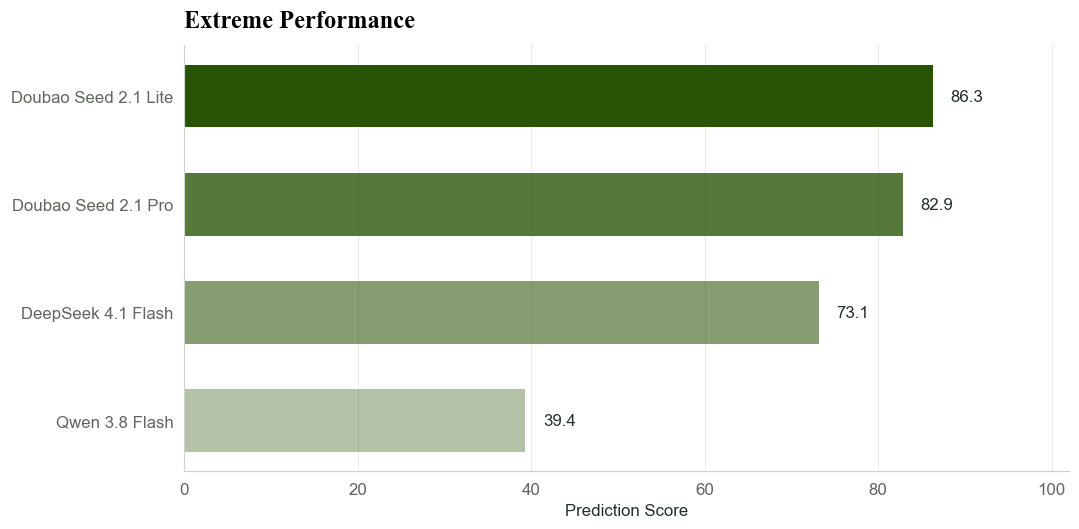

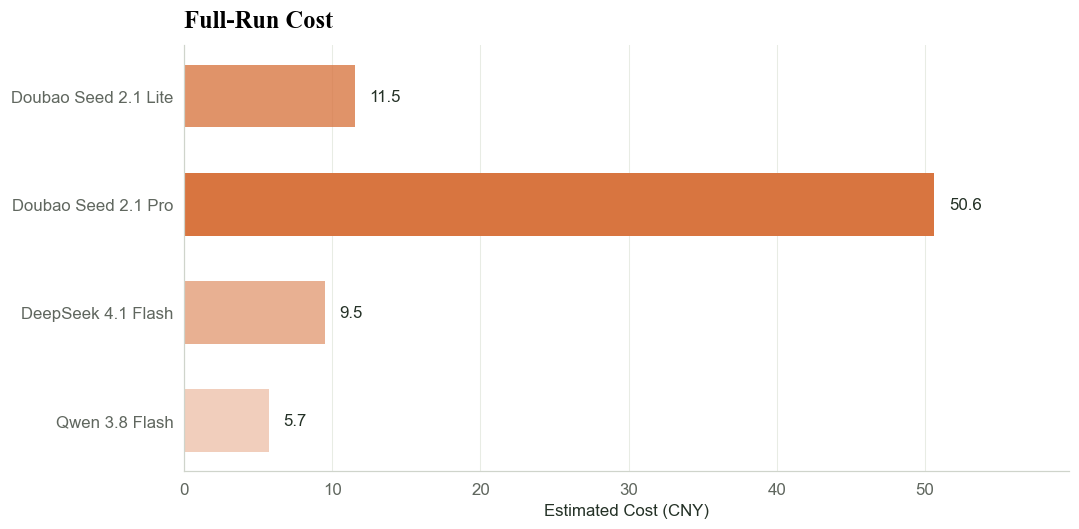

In [10]:
# C6 — Separate Role LLM performance and fixed model-budget comparisons.
# DeepSeek and Qwen use their completed mainline Role-with-history scores.
# Costs below are user-specified approximate full-run amounts, not token-derived costs.
C6_SCORE_SIZE = (10, 5)
C6_COST_SIZE = (10, 5)
C6_ORDER = ['Doubao Lite', 'Doubao Pro', 'DeepSeek', 'Qwen 3.8 Flash']
C6_LABELS = ['Doubao Seed 2.1 Lite', 'Doubao Seed 2.1 Pro',
             'DeepSeek 4.1 Flash', 'Qwen 3.8 Flash']
C6_COST_CNY = [11.5, 50.6, 9.5, 5.7]
C6_BAR_HEIGHT = .58

# Qwen uses the same Role-with-history score and center-day averaging as Doubao.
backends = pd.read_csv('figures/data/role_backend_comparison.csv').set_index('model').reindex(C6_ORDER)
# Use the saved Role LLM with-history Extreme center-day score.
deepseek = pd.read_csv('mainline/results/deepseek_flash_available_projected_run01/summary.csv').set_index('method')
backends.loc['DeepSeek', 'score'] = deepseek.loc['role_with_history', 'Extreme']
backends.loc['DeepSeek', 'placeholder'] = False
y = np.arange(len(C6_ORDER))
fig, ax = plt.subplots(figsize=C6_SCORE_SIZE)
values = backends['score']
ax.barh(y, values, color=rank_colors(values,GREEN), height=C6_BAR_HEIGHT)
for row,(value,pending) in enumerate(zip(values,backends.placeholder)):
    label = '0.0 · Pending' if pending else f'{value:.1f}'
    ax.text(value+2,row,label,va='center',color=GRAY if pending else INK,fontsize=11)
ax.set_yticks(y,C6_LABELS); ax.invert_yaxis()
ax.set_xlim(0,102); ax.set_xlabel('Prediction Score')
ax.set_title('Extreme Performance',loc='left'); style(ax,'x')
finish(fig,'C6_role_llm_performance')

fig, ax = plt.subplots(figsize=C6_COST_SIZE)
ax.barh(y,C6_COST_CNY,color=rank_colors(C6_COST_CNY,ORANGE),height=C6_BAR_HEIGHT)
for row,value in enumerate(C6_COST_CNY):
    ax.text(value+1,row,f'{value:.1f}',va='center',fontsize=11,color=INK)
ax.set_yticks(y,C6_LABELS); ax.invert_yaxis()
ax.set_xlim(0,max(C6_COST_CNY)*1.18); ax.set_xlabel('Estimated Cost (CNY)')
ax.set_title('Full-Run Cost',loc='left'); style(ax,'x')
finish(fig,'C6_model_cost')


## 不同群体极端天气决策对比及预测准确率对比（学生特别差，可能因为样本少、暑期非暑期波动大）

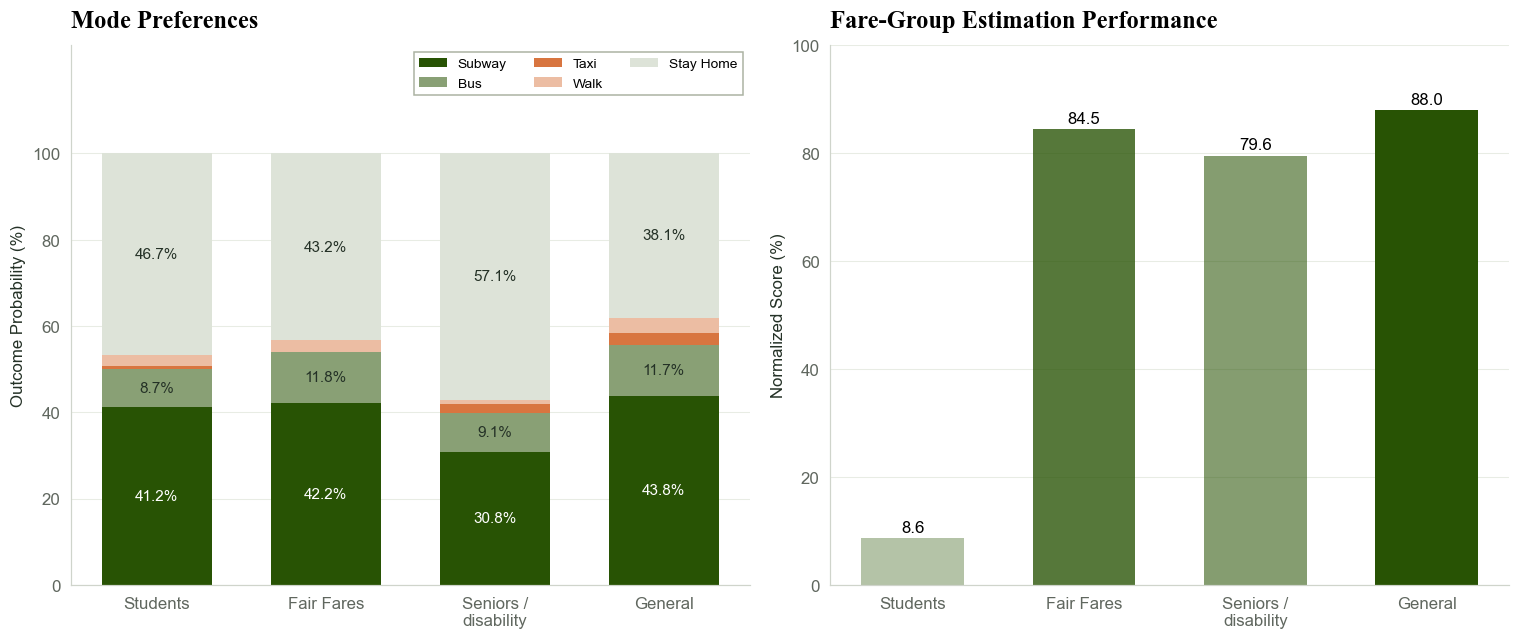

In [8]:
# C7 — Mode shares and bounded prediction scores, using the main Role LLM.
# Mean WAPE = 1 - original_score/100; normalized score = 100/(1 + mean WAPE).
# This is a different, explicitly named score, not the C1/C6 score or classification accuracy.
C7_SIZE = (14, 6)
C7_GROUP_ORDER = ['students', 'fair_fare', 'seniors_disability', 'general']
C7_GROUP_LABELS = ['Students', 'Fair Fares', 'Seniors /\ndisability', 'General']
C7_ACTIONS = ['subway', 'bus', 'taxi', 'walk', 'stay_home']
C7_MODE_COLORS = [GREEN, tint(GREEN,.55), ORANGE, tint(ORANGE,.48), '#DDE3D8']

choices = pd.read_csv('figures/data/group_extreme_choices.csv').set_index('group').reindex(C7_GROUP_ORDER)
group_scores = pd.read_csv('figures/data/group_extreme_scores.csv')
group_scores = group_scores[group_scores.method=='role_with_history'].set_index('group').reindex(C7_GROUP_ORDER)
group_scores['mean_wape'] = 1-group_scores.score/100
group_scores['normalized_score'] = 100/(1+group_scores.mean_wape)
group_scores.reset_index().to_csv(f'{FIGURE_DIR}/data/group_extreme_normalized_scores.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=C7_SIZE)
x = np.arange(4); bottom = np.zeros(4)
for action,color in zip(C7_ACTIONS,C7_MODE_COLORS):
    values = choices['p_'+action].to_numpy()*100
    axes[0].bar(x,values,bottom=bottom,color=color,width=.65,label=action.replace('_',' ').title())
    for i,value in enumerate(values):
        if value>=7:
            axes[0].text(i,bottom[i]+value/2,f'{value:.1f}%',ha='center',va='center',fontsize=10,
                         color='white' if color in [GREEN,ORANGE] else INK)
    bottom += values
axes[0].set_ylim(0,125); axes[0].set_yticks([0,20,40,60,80,100])
axes[0].set_ylabel('Outcome Probability (%)'); axes[0].set_title('Mode Preferences',loc='left')
add_legend(axes[0],loc='upper right',ncol=3)
values = group_scores.normalized_score
bars = axes[1].bar(x,values,color=rank_colors(values,GREEN),width=.6)
for b,value in zip(bars,values):
    axes[1].text(b.get_x()+b.get_width()/2,value+1.2,f'{value:.1f}',ha='center',fontsize=11)
axes[1].set_ylim(0,100); axes[1].set_ylabel('Normalized Score (%)')
axes[1].set_title('Fare-Group Estimation Performance',loc='left')
for ax in axes:ax.set_xticks(x,C7_GROUP_LABELS);style(ax)
finish(fig,'C7_fare_group_choices_scores')


#  角色LLM决策关键词

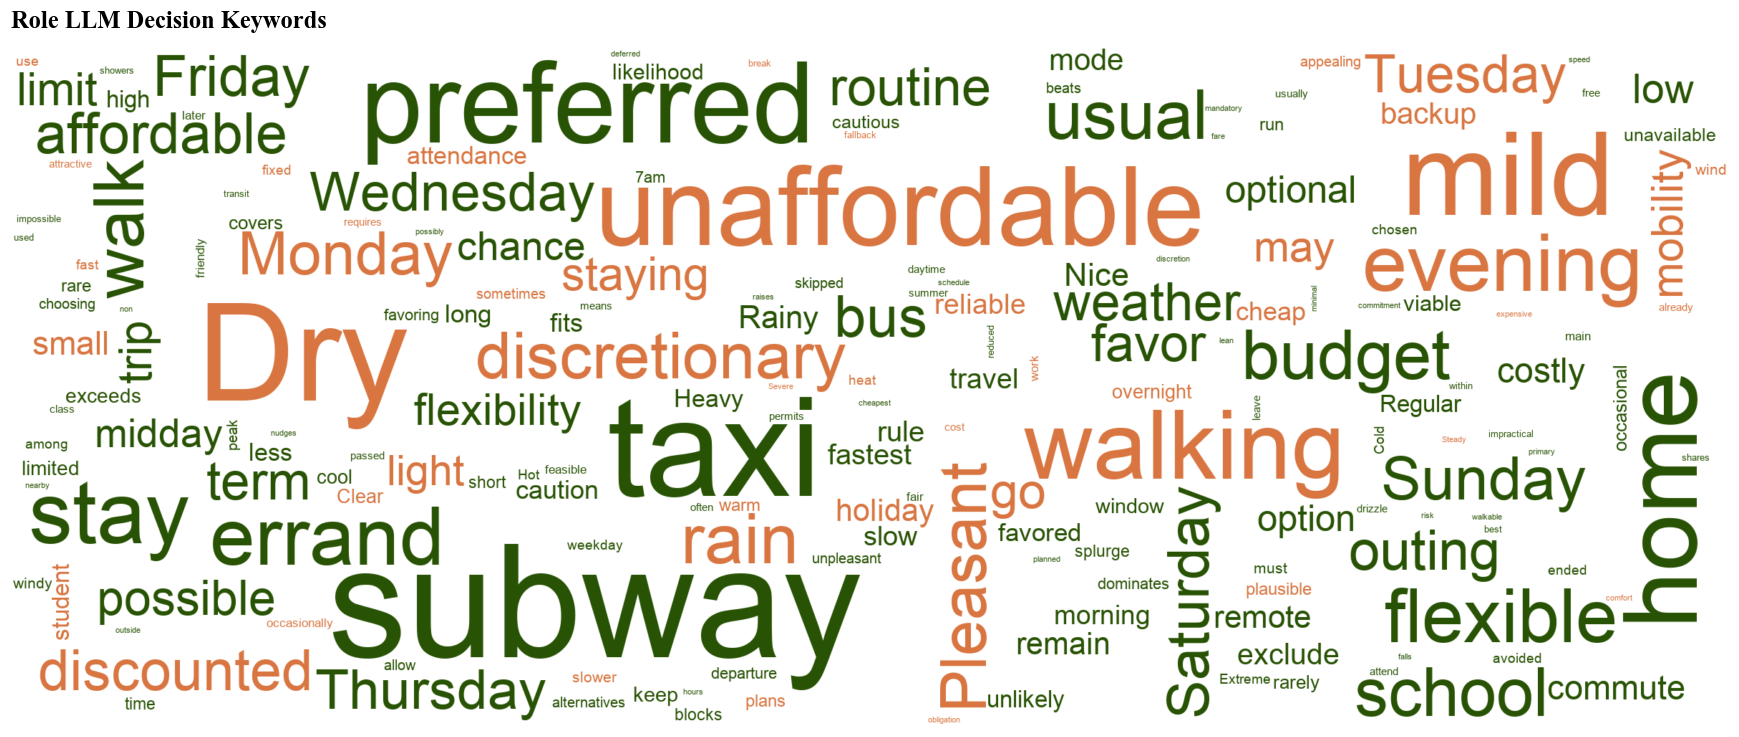

In [9]:
# C8 — Dense word cloud from the actual Lite role few-shot reasons (one per request).
# Repeated placement fills gaps; no unrelated words or extra model text are invented.
C8_SIZE = (16, 7.4)
C8_MAX_WORDS = 650
C8_REPEAT = True
C8_MIN_FONT = 9
C8_MAX_FONT = 220
C8_RANDOM_STATE = 5011
C8_EXTRA_STOPWORDS = {'would','could','might','because','given','today','day','need','choose',
                     'choice','prefer','likely','brief','reason','one','potential','making',
                     'take','taking','makes','make','still','will','rather','mostly','much'}

reasons = json.load(open('figures/data/lite_role_reasons.json'))
text = ' '.join(r['reason'] for r in reasons if r['method']=='role_with_history')
cloud = WordCloud(width=2400, height=950, background_color='white', font_path=WORD_FONT,
                  max_words=C8_MAX_WORDS, repeat=C8_REPEAT, min_font_size=C8_MIN_FONT,
                  max_font_size=C8_MAX_FONT, margin=4, prefer_horizontal=.93,
                  relative_scaling=.5, random_state=C8_RANDOM_STATE,
                  stopwords=STOPWORDS|C8_EXTRA_STOPWORDS, collocations=False)
frequencies = cloud.process_text(text)
cloud.generate_from_frequencies(frequencies)
def word_color(word, font_size, position, orientation, random_state=None, **kwargs):
    return ORANGE if random_state.random()<.22 else GREEN
cloud.recolor(color_func=word_color, random_state=C8_RANDOM_STATE)
fig, ax = plt.subplots(figsize=C8_SIZE)
ax.imshow(cloud, interpolation='bilinear'); ax.axis('off')
ax.set_title('Role LLM Decision Keywords', loc='left', fontfamily=TITLE_FONT,
             fontweight='bold', fontsize=23, pad=16)
finish(fig, 'C8_role_reason_wordcloud')
pd.DataFrame(Counter(frequencies).most_common(), columns=['word','frequency']).to_csv(f'{FIGURE_DIR}/data/word_frequencies.csv', index=False)
